In [1]:
%pip install -q pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


# 04. SVB case study: what happened in March 2023

Silicon Valley Bank, called SVB, was a US bank that served mainly
technology companies and venture capital firms. It failed on March 10,
2023. This notebook explains the mechanics in plain words, then checks
the market context with our own data. It does not use the old
AI-trading.py script from the original repo as evidence, because that
script was never verified. It also does not claim a trading strategy
would have predicted or profited from the failure.

## Three ideas you need first

Duration risk. A bond is a loan to a borrower, like the US government,
that pays interest and returns the principal later. When interest rates
rise, old bonds that pay low interest become less attractive, so their
market price falls. The longer the bond has left to run, the more its
price falls for the same rate rise. That sensitivity is called duration.
A bank that buys long bonds at low rates is taking duration risk.

Held to maturity accounting. A bank can label some bonds as held to
maturity, meaning it plans to keep them until they repay. Those bonds
are carried on the books at their original cost, not at their current
market price. The gap between book value and market value is called an
unrealized loss. It is real in economic terms, but it does not show up
in headline profit until the bank sells. If the bank is forced to sell
to meet withdrawals, the unrealized loss becomes a realized loss at once.

A bank run. Banks lend out most deposits, so they do not hold enough
cash to repay every depositor on the same day. That works fine when
withdrawals are spread out. It breaks when many depositors ask for
their money at once, especially depositors with very large balances
above the FDIC insurance limit of 250,000 dollars. Those depositors
have the most reason to run first, because only the insured part is
guaranteed in a normal failure.

## Timeline, from official sources

The Federal Reserve published a review of its supervision of SVB in
April 2023. The FDIC and the California regulator closed the bank on
March 10, 2023. On March 12, 2023, the Treasury, the Federal Reserve,
and the FDIC announced that all deposits at SVB, insured and
uninsured, would be protected under a systemic risk exception, and the
Federal Reserve created a lending program for banks. Those are official
actions, and we report them as such. Where sources disagree on a detail,
for example the exact share of uninsured deposits, we give a range and
say so in the notes below.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
ROOT = Path("..").resolve()
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
PROC = ROOT / "data" / "processed"
print("Charts will be saved to:", CHARTS)

Charts will be saved to: /home/hatch/workspace/repo-builds/finance-analytics/charts


In [3]:
# SVB facts table, sourced, not computed from market data.
# Sources: Federal Reserve review of SVB supervision, April 2023;
# SVB Financial Group 10-K for year end 2022, via the Federal Reserve
# and FASB comment letter summaries; FDIC and joint agency statements.
svb = pd.DataFrame([
    {"item": "Total assets at failure, about", "value": "209 billion dollars"},
    {"item": "Held to maturity bonds, book value, year end 2022", "value": "91 billion dollars"},
    {"item": "Held to maturity bonds, fair value, year end 2022", "value": "76 billion dollars"},
    {"item": "Unrealized loss on held to maturity bonds", "value": "about 15.2 billion dollars"},
    {"item": "Total equity at year end 2022", "value": "about 16.3 billion dollars"},
    {"item": "Available for sale bonds sold on March 8, 2023", "value": "about 21 billion dollars"},
    {"item": "Loss realized on that sale", "value": "about 1.8 billion dollars"},
    {"item": "Capital raise announced March 8, 2023", "value": "about 2.25 billion dollars"},
    {"item": "Withdrawals attempted on March 9, 2023", "value": "about 42 billion dollars"},
    {"item": "Bank closed", "value": "March 10, 2023"},
    {"item": "All deposits protected, joint announcement", "value": "March 12, 2023"},
])
print(svb.to_string(index=False))
print()
print("Check: 91 minus 76 is 15, which matches the reported unrealized loss of about 15.2 billion, allowing for rounding.")
print("Check: 42 billion is about one quarter of total deposits, consistent with reports that it was roughly 25 percent.")
print("Uninsured share: reports range from about 88 percent to about 94 percent depending on the measure and date. We report the range, not a single exact figure.")

                                             item                      value
                   Total assets at failure, about        209 billion dollars
Held to maturity bonds, book value, year end 2022         91 billion dollars
Held to maturity bonds, fair value, year end 2022         76 billion dollars
        Unrealized loss on held to maturity bonds about 15.2 billion dollars
                    Total equity at year end 2022 about 16.3 billion dollars
   Available for sale bonds sold on March 8, 2023   about 21 billion dollars
                       Loss realized on that sale  about 1.8 billion dollars
            Capital raise announced March 8, 2023 about 2.25 billion dollars
           Withdrawals attempted on March 9, 2023   about 42 billion dollars
                                      Bank closed             March 10, 2023
       All deposits protected, joint announcement             March 12, 2023

Check: 91 minus 76 is 15, which matches the reported unrealized loss of abo

10 year yield, Aug 2020 low in our data: {'date': Timestamp('2020-08-04 00:00:00'), 'yield_10y': 0.52}
{'date': Timestamp('2021-01-04 00:00:00'), 'yield_10y': 0.93, 'yield_2y': 0.11, 'spread_10y_minus_2y': 0.8200000000000001}
{'date': Timestamp('2023-03-31 00:00:00'), 'yield_10y': 3.48, 'yield_2y': 4.06, 'spread_10y_minus_2y': -0.5799999999999996}


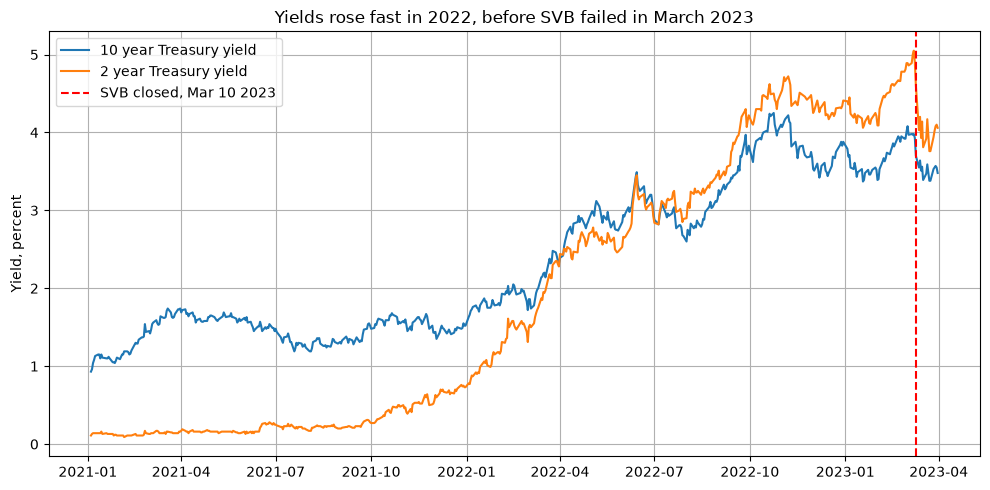

In [4]:
rates = pd.read_csv(PROC / "svb_window_rates.csv", parse_dates=["date"])
print("10 year yield, Aug 2020 low in our data:", rates.loc[rates["yield_10y"].idxmin(), ["date", "yield_10y"]].to_dict())
window = rates[(rates["date"] >= "2021-01-01") & (rates["date"] <= "2023-03-31")]
print(window.iloc[0].to_dict())
print(window.iloc[-1].to_dict())
fig, ax = plt.subplots()
ax.plot(window["date"], window["yield_10y"], label="10 year Treasury yield")
ax.plot(window["date"], window["yield_2y"], label="2 year Treasury yield")
ax.axvline(pd.Timestamp("2023-03-10"), color="red", linestyle="--", label="SVB closed, Mar 10 2023")
ax.set_ylabel("Yield, percent")
ax.set_title("Yields rose fast in 2022, before SVB failed in March 2023")
ax.legend()
plt.tight_layout()
plt.savefig(CHARTS / "04_rates_2020_2023.png", dpi=150)
plt.show()

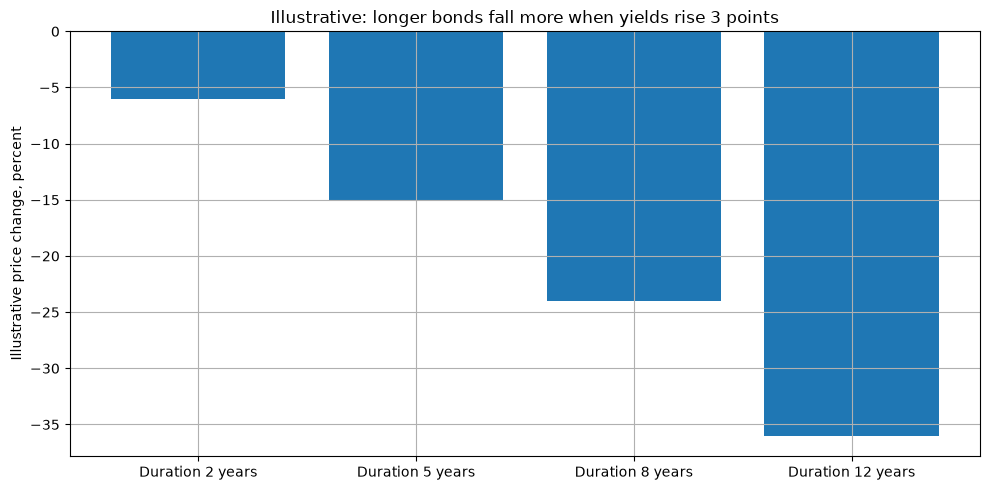

Duration 2: about -6.0 percent
Duration 5: about -15.0 percent
Duration 8: about -24.0 percent
Duration 12: about -36.0 percent
SVB reported held to maturity loss share: about 16.7 percent


In [5]:
# Illustrative bond math only. This is NOT SVB's actual portfolio.
# Formula in plain words: price change in percent is about minus duration
# times the change in yield in percentage points.
# Example: a bond with duration 8, if yields rise 3 points, price falls about 24 percent.
# SVB's reported loss was about 15.2 on 91, or about 16.7 percent, which is
# in the same ballpark as this kind of long bond math, but the exact
# duration of SVB's portfolio is not recovered here from public summaries.
durations = [2, 5, 8, 12]
yield_rise = 3.0
losses = [-d * yield_rise for d in durations]
fig, ax = plt.subplots()
ax.bar([f"Duration {d} years" for d in durations], losses)
ax.set_ylabel("Illustrative price change, percent")
ax.set_title("Illustrative: longer bonds fall more when yields rise 3 points")
plt.tight_layout()
plt.savefig(CHARTS / "04_illustrative_bond.png", dpi=150)
plt.show()
for d, loss in zip(durations, losses):
    print(f"Duration {d}: about {loss} percent")
print("SVB reported held to maturity loss share: about", round(15.2 / 91 * 100, 1), "percent")

VIX in March 2023, around the failure:
      date   vix
2023-03-01 20.58
2023-03-02 19.59
2023-03-03 18.49
2023-03-06 18.61
2023-03-07 19.59
2023-03-08 19.11
2023-03-09 22.61
2023-03-10 24.80
2023-03-13 26.52
2023-03-14 23.73
2023-03-15 26.14
2023-03-16 22.99
2023-03-17 25.51
2023-03-20 24.15


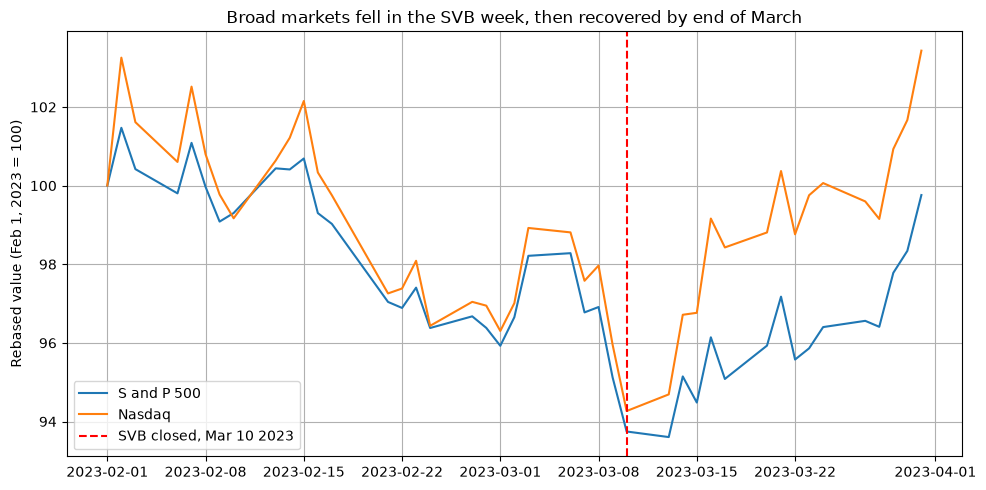

In [6]:
mkt = pd.read_csv(PROC / "svb_window_markets.csv", parse_dates=["date"])
vix = pd.read_csv(PROC / "vix_daily.csv", parse_dates=["date"])
vix_mar = vix[(vix["date"] >= "2023-03-01") & (vix["date"] <= "2023-03-20")]
print("VIX in March 2023, around the failure:")
print(vix_mar.to_string(index=False))
fig, ax = plt.subplots()
ax.plot(mkt["date"], mkt["sp500_rebased_feb1"], label="S and P 500")
ax.plot(mkt["date"], mkt["nasdaq_rebased_feb1"], label="Nasdaq")
ax.axvline(pd.Timestamp("2023-03-10"), color="red", linestyle="--", label="SVB closed, Mar 10 2023")
ax.set_ylabel("Rebased value (Feb 1, 2023 = 100)")
ax.set_title("Broad markets fell in the SVB week, then recovered by end of March")
ax.legend()
plt.tight_layout()
plt.savefig(CHARTS / "04_market_svb_window.png", dpi=150)
plt.show()

## Lessons, stated carefully

First, duration risk is not a footnote. When yields rose from about
0.5 percent on the 10 year Treasury in August 2020 to about 4.0 percent
in early March 2023 in our FRED data, long bonds lost a large share of
their market value. A bank that funded those bonds with deposits that
could leave quickly was exposed on both sides: asset values down,
funding able to run.

Second, concentration matters. A deposit base dominated by a small
number of large, connected, uninsured depositors can move together.
On March 9, 2023, about 42 billion dollars was withdrawn in one day.
That speed, not just the size of the loss, is what closed the bank.

Third, accounting labels do not change economics. Held to maturity
accounting kept the unrealized loss off headline profit, but the loss
was disclosed in footnotes, and it became real the moment the bank had
to sell. Anyone reading only the headline equity number, about 16.3
billion dollars, without the footnote loss of about 15.2 billion
dollars, would have missed how thin the cushion really was.

Fourth, the broad market did not collapse. The S and P 500 fell from
100 on February 1, 2023 to about 93.7 on March 10, and was back to about
99.8 by March 31. The Nasdaq was above its February 1 level by March 31.
The lesson is not that every bank failure causes a market crash. It is
that a single bank can fail fast from liquidity and interest rate risk
even while the broad market recovers.